# 4 аугментации для ASR

Добро пожаловать на ~~несогласованную~~ демонстрацию наших аугментаций!

Запускай ноутбук из папки `demo` с ядром Python из окружения проекта. Используется готовая моно-запись 16000 Гц из `demo/sample`.

In [84]:
from pathlib import Path
import sys
import json

project = Path("..").resolve()
sys.path.insert(0, str(project))

import torch
import torchaudio
import matplotlib.pyplot as plt
from hydra import compose, initialize_config_dir
from hydra.utils import instantiate
from omegaconf import OmegaConf
from IPython.display import Audio, Image, display

audio_path = project / "demo/sample/audio/7850-286674-0000.flac"
output_dir = project / "data/augmentation_notebook"
output_dir.mkdir(parents=True, exist_ok=True)
seed = 42

audio, sample_rate = torchaudio.load(str(audio_path))
seconds = audio.shape[-1] / sample_rate
settings = OmegaConf.load(project / "src/configs/transforms/instance_transforms/example.yaml")
features = instantiate(settings.inference.get_spectrogram)
original = features(audio)
torchaudio.save(str(output_dir / "original.wav"), audio, sample_rate)
summary = {"source": str(audio_path), "sample_rate": sample_rate, "seed": seed, "variants": {}}

experiments = {
    "speed": "exp_3_speed", "noise": "exp_4_noise",
    "frequency_mask": "exp_5_frequency_mask", "time_mask": "exp_6_time_mask",
}
configs = {}
with initialize_config_dir(config_dir=str(project / "src/configs"), version_base=None):
    for name, experiment in experiments.items():
        configs[name] = compose(config_name="мои экспы/" + experiment)


def show_comparison(name, augmented, augmented_seconds, overrides=None):
    figure, axes = plt.subplots(2, 1, figsize=(12, 6))
    for axis, spectrum, duration, title in zip(
        axes, [original, augmented], [seconds, augmented_seconds], ["Original", name]
    ):
        axis.imshow(
            spectrum.detach().cpu().numpy(), aspect="auto", origin="lower",
            cmap="magma", vmin=-3, vmax=3, extent=[0, duration, 0, spectrum.shape[0]],
        )
        axis.set(title=title, xlabel="Time, seconds", ylabel="Mel band")
    figure.tight_layout()
    destination = output_dir / (name + ".png")
    figure.savefig(destination)
    plt.close(figure)
    display(Image(filename=str(destination)))
    transforms = configs[name].datasets.train.instance_transforms
    transform_config = transforms.audio if name in ("speed", "noise") else transforms.spectrogram
    summary["variants"][name] = {
        "experiment": experiments[name],
        "settings": OmegaConf.to_container(transform_config, resolve=True),
        "demo_overrides": overrides or {},
        "original_seconds": seconds,
        "augmented_seconds": augmented_seconds,
        "spectrogram_shape": list(augmented.shape),
    }

log_mel = features.mel(audio).squeeze(0).clamp_min(features.eps).log()
mel_mean = log_mel.mean(-1, keepdim=True)
mel_std = log_mel.std(-1, keepdim=True, unbiased=False).clamp_min(features.eps)
inverse_mel = torchaudio.transforms.InverseMelScale(
    n_stft=513, n_mels=128, sample_rate=sample_rate, driver="gelsd",
)
griffin_lim = torchaudio.transforms.GriffinLim(
    n_fft=1024, win_length=400, hop_length=160, n_iter=64, length=audio.shape[-1],
)


def reconstruct(spectrum):
    mel_power = (spectrum * mel_std + mel_mean).exp()
    linear_power = inverse_mel(mel_power)
    with torch.random.fork_rng():
        torch.manual_seed(seed)
        restored = griffin_lim(linear_power)
    return restored.unsqueeze(0)


restored_original = reconstruct(original)
reconstruction_gain = 0.8 / restored_original.abs().max().clamp_min(1e-8)
restored_original = restored_original * reconstruction_gain
torchaudio.save(str(output_dir / "reconstructed_original.wav"), restored_original, sample_rate)


## Исходная запись

Послушаем исходное аудио. В каждой паре спектрограмм сверху показан оригинал, а снизу измененная запись.

In [85]:
display(Audio(filename=str(output_dir / "original.wav")))
reference_path = project / "demo/sample/transcriptions" / (audio_path.stem + ".txt")
print("Исходная запись:", reference_path.read_text().strip())

Исходная запись: a person would think that after a family had lived so long in a place all the neighbors would be fond of them yet it is not so


## 1. Speed perturbation

Выберем коэффициент 0.5. запись станет в 2 раза медленнее а голос в 2 раза ниже (звучит пугающе). Частота сохранённого WAV остаётся 16000 Гц.

В обучении коэффициент выбирается из `[0.9, 1.0, 1.1]`, чуть убыстряем чуть уменьшаем, оставляем как есть. Примеры можно также ниже посомтреть.

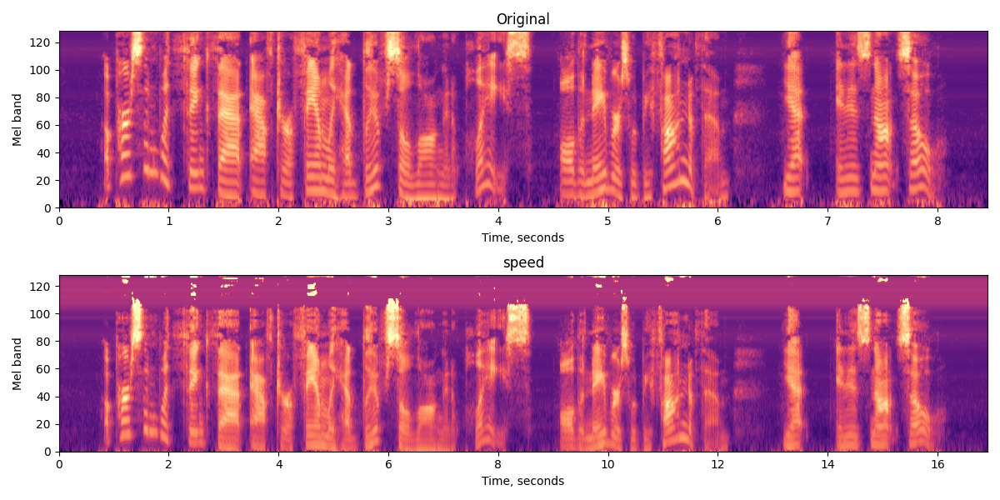

Длительность: 8.46 → 16.91 с


In [86]:
torch.manual_seed(seed)
speed = instantiate(configs["speed"].datasets.train.instance_transforms.audio, factors=[0.5])
speed_audio = speed(audio)
speed_seconds = speed_audio.shape[-1] / sample_rate
torchaudio.save(str(output_dir / "speed.wav"), speed_audio, sample_rate)
display(Audio(filename=str(output_dir / "speed.wav")))
show_comparison("speed", features(speed_audio), speed_seconds, {"factors": [0.5]})
print(f"Длительность: {seconds:.2f} → {speed_seconds:.2f} с")

Запись 0.9:

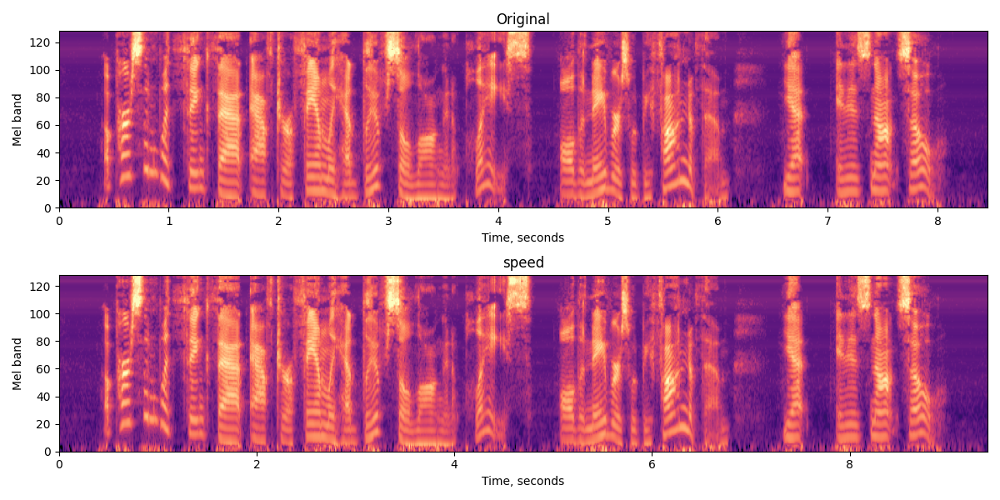

Длительность: 8.46 → 9.39 с


In [87]:
torch.manual_seed(seed)
speed = instantiate(configs["speed"].datasets.train.instance_transforms.audio, factors=[0.9])
speed_audio = speed(audio)
speed_seconds = speed_audio.shape[-1] / sample_rate
torchaudio.save(str(output_dir / "speed.wav"), speed_audio, sample_rate)
display(Audio(filename=str(output_dir / "speed.wav")))
show_comparison("speed", features(speed_audio), speed_seconds, {"factors": [0.9]})
print(f"Длительность: {seconds:.2f} → {speed_seconds:.2f} с")

Запись 1.1:

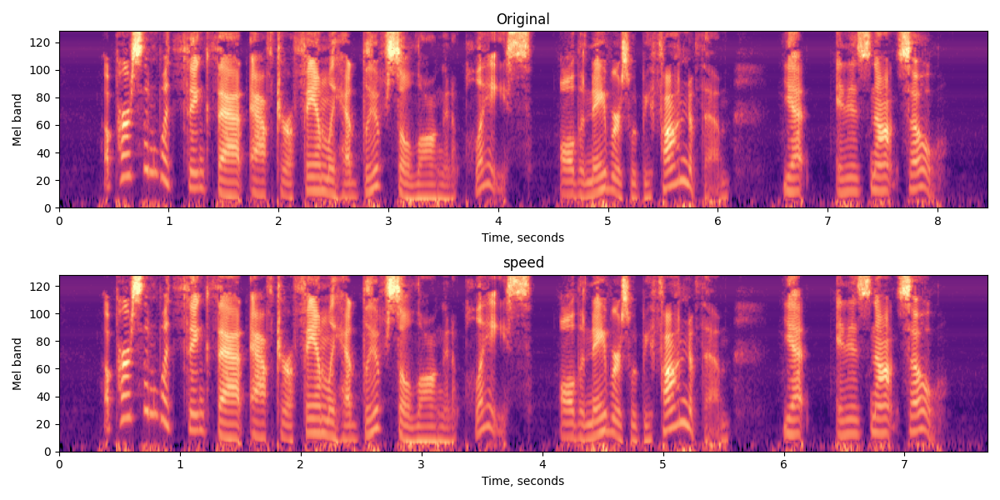

Длительность: 8.46 → 7.69 с


In [88]:
torch.manual_seed(seed)
speed = instantiate(configs["speed"].datasets.train.instance_transforms.audio, factors=[1.1])
speed_audio = speed(audio)
speed_seconds = speed_audio.shape[-1] / sample_rate
torchaudio.save(str(output_dir / "speed.wav"), speed_audio, sample_rate)
display(Audio(filename=str(output_dir / "speed.wav")))
show_comparison("speed", features(speed_audio), speed_seconds, {"factors": [1.1]})
print(f"Длительность: {seconds:.2f} → {speed_seconds:.2f} с")

## 2. Добавление шума

Добавляем случайный шум с SNR от 15 до 30 дБ. Чем меньше SNR, тем сильнее шум.

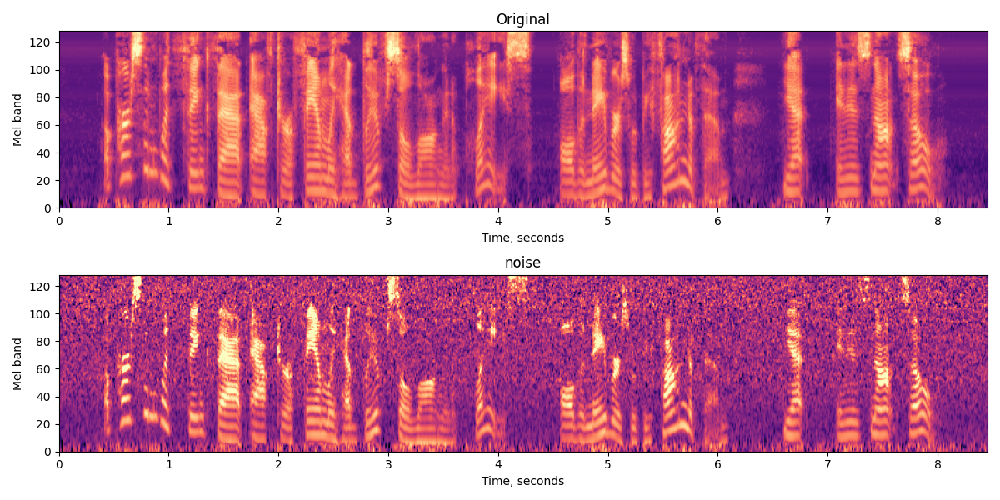

Измеренный SNR: 18.08 дБ


In [89]:
torch.manual_seed(seed)
add_noise = instantiate(configs["noise"].datasets.train.instance_transforms.audio, p=1.0) # в конфиге обучения p=0.5
noisy_audio = add_noise(audio)
torchaudio.save(str(output_dir / "noise.wav"), noisy_audio, sample_rate)
display(Audio(filename=str(output_dir / "noise.wav")))
show_comparison("noise", features(noisy_audio), seconds, {"p": 1.0})
noise = noisy_audio - audio
snr = float(10 * torch.log10(audio.square().mean() / noise.square().mean()))
summary["variants"]["noise"]["measured_snr_db"] = snr
print(f"Измеренный SNR: {snr:.2f} дБ")

## 3. Frequency masking

N случайных маски закрывают полосы частот. Ширина каждой выбирается от 0 до 12 mel-полос. Значения признаков заменяются нулями.

Попробуем примерно восстановить, как бы звучала восстановленная запись для демо.

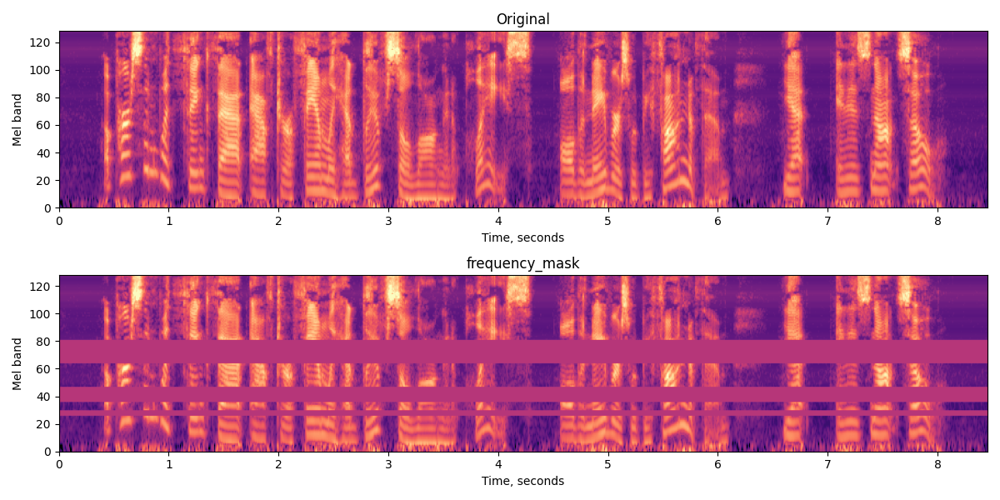

Восстановленный оригинал


Восстановленное аудио после frequency masking


In [90]:
torch.manual_seed(seed)
frequency_mask = instantiate(configs["frequency_mask"].datasets.train.instance_transforms.spectrogram, num_masks=5)
frequency_spectrum = frequency_mask(original)
show_comparison("frequency_mask", frequency_spectrum, seconds, {"num_masks": 5})
frequency_audio = reconstruct(frequency_spectrum) * reconstruction_gain
torchaudio.save(str(output_dir / "frequency_mask.wav"), frequency_audio, sample_rate)
print("Восстановленный оригинал")
display(Audio(filename=str(output_dir / "reconstructed_original.wav")))
print("Восстановленное аудио после frequency masking")
display(Audio(filename=str(output_dir / "frequency_mask.wav")))

## 4. Time masking

N случайных масок закрывают участки времени на всех частотах. Ширина каждой — не больше 40 кадров и 5% длины спектрограммы.

Здесь показан TimeMasking из exp6, потом я сделала еще TimeMaskingV2, где число масок зависит от длительности.

Опять попробуем примерно восстановить, как бы звучала восстановленная запись для демо.

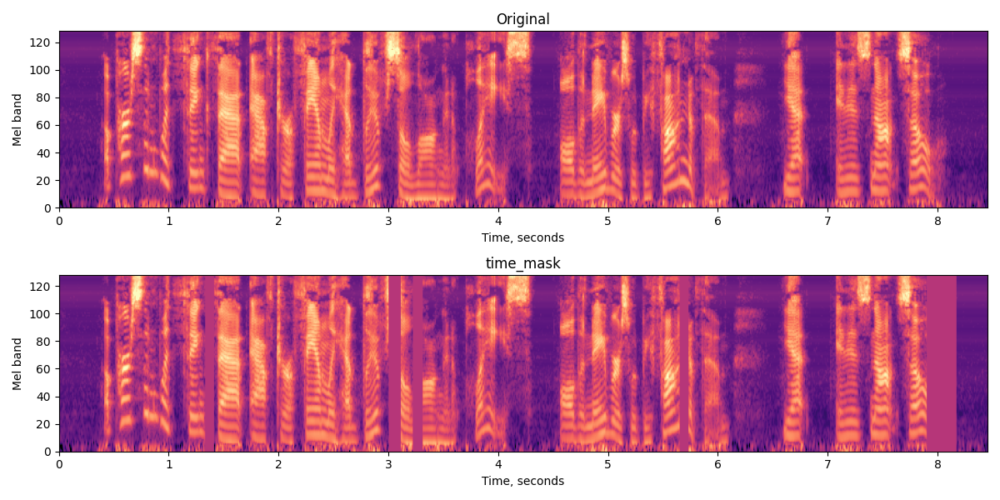

Восстановленный оригинал


Восстановленное аудио после time masking


In [91]:
torch.manual_seed(seed)
time_mask = instantiate(configs["time_mask"].datasets.train.instance_transforms.spectrogram, num_masks=5)
time_spectrum = time_mask(original)
show_comparison("time_mask", time_spectrum, seconds, {"num_masks": 5})
time_audio = reconstruct(time_spectrum) * reconstruction_gain
torchaudio.save(str(output_dir / "time_mask.wav"), time_audio, sample_rate)
print("Восстановленный оригинал")
display(Audio(filename=str(output_dir / "reconstructed_original.wav")))
print("Восстановленное аудио после time masking")
display(Audio(filename=str(output_dir / "time_mask.wav")))

(здесь в конце как раз и слышно это перекрытие)

## run в Comet
Для этого нужно:
1. переведи `save_comet` из False в True. 
2. При необходимости выполнить `comet login`
3. Выполнить команду, напечатанную в терминале

Ячейка сохраняет показанные результаты в архив: шесть аудио, четыре сравнения спектрограмм и параметры.

In [92]:
save_comet = False
if save_comet:
    from comet_ml import OfflineExperiment

    (output_dir / "summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2) + "\n")
    comet_dir = output_dir / "comet"
    comet_dir.mkdir(parents=True, exist_ok=True)
    experiment = OfflineExperiment(
        project_name="hw1_asr", offline_directory=str(comet_dir), auto_metric_logging=False,
    )
    try:
        experiment.set_name("augmentation_demo_four_types")
        experiment.log_parameters(summary)
        experiment.log_audio(str(output_dir / "original.wav"), file_name="original.wav")
        experiment.log_audio(str(output_dir / "reconstructed_original.wav"), file_name="reconstructed_original.wav")
        for name in summary["variants"]:
            experiment.log_image(str(output_dir / (name + ".png")), name=name)
            label = "reconstructed_" + name if name.endswith("mask") else name
            experiment.log_audio(str(output_dir / (name + ".wav")), file_name=label + ".wav")
        experiment.log_asset(str(output_dir / "summary.json"))
        experiment_key = experiment.get_key()
    finally:
        experiment.end()
    print(f'comet upload --project-name hw1_asr "{comet_dir / (experiment_key + ".zip")}"')

И анекдот напоследок:

Японцы изобрели часы, которые, услышав мат, перескакивают на минуту вперед. Решили опробовать.

* Повесили в японский бар на 24 часа. Приходят — часы идут на 2 минуты вперед.
* Повесили в английский паб на 24 часа. Приходят — часы идут на 5 минут вперед.
* Повесили в русский бар. Приходят через сутки — часов нет.
Подходят к бармену:

--- Мы вчера сюда часы повесили, где они?

Бармен (удивленно):

--- Аааа... так это были часы? А мы думали — нахрена нам зимой вентилятор?